In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train_final=pd.read_csv("../data/train_final.csv")
test_final=pd.read_csv("../data/test_final.csv")

features = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]

X_train=train_final[features]
y_train=train_final["Outcome"]

X_test=test_final[features]
y_test=test_final["Outcome"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("Missing values:", X_train.isnull().sum().sum())
print("Diabetes share:", round(y_train.mean() * 100, 1), "%")



X_train: (614, 8)
y_train: (614,)
Missing values: 0
Diabetes share: 34.9 %


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


models={

    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    
}

In [4]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained")

Logistic Regression trained
KNN trained
Decision Tree trained
Random Forest trained


In [5]:
sample = X_train.head(5)

predictions = pd.DataFrame({
    name: model.predict_proba(sample)[:, 1].round(2)
    for name, model in models.items()
})

print("Predicted chance of diabetes:")
print(predictions)
print()
print("Actual outcomes:", y_train.head(5).tolist())

Predicted chance of diabetes:
   Logistic Regression  KNN  Decision Tree  Random Forest
0                 0.05  0.2            0.0           0.02
1                 0.33  0.6            0.0           0.12
2                 0.16  0.0            0.0           0.05
3                 0.39  0.4            0.0           0.20
4                 0.22  0.0            0.0           0.07

Actual outcomes: [0, 0, 0, 0, 0]


In [6]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

probas = {}
for name, model in models.items():
    probas[name] = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    print(name, "done")


Logistic Regression done
KNN done
Decision Tree done
Random Forest done


In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix

rows = []
for name, p in probas.items():
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_train, pred),
        "Precision": precision_score(y_train, pred),
        "Recall": recall_score(y_train, pred),
        "F1": f1_score(y_train, pred),
        "ROC-AUC": roc_auc_score(y_train, p),
        "False negatives": fn,
        "False positives": fp
    })

results = pd.DataFrame(rows).set_index("Model")
print(results.round(3))

                     Accuracy  Precision  Recall     F1  ROC-AUC  \
Model                                                              
Logistic Regression     0.787      0.758   0.570  0.651    0.844   
KNN                     0.731      0.628   0.561  0.593    0.784   
Decision Tree           0.668      0.521   0.570  0.545    0.645   
Random Forest           0.770      0.695   0.607  0.648    0.818   

                     False negatives  False positives  
Model                                                  
Logistic Regression               92               39  
KNN                               94               71  
Decision Tree                     92              112  
Random Forest                     84               57  


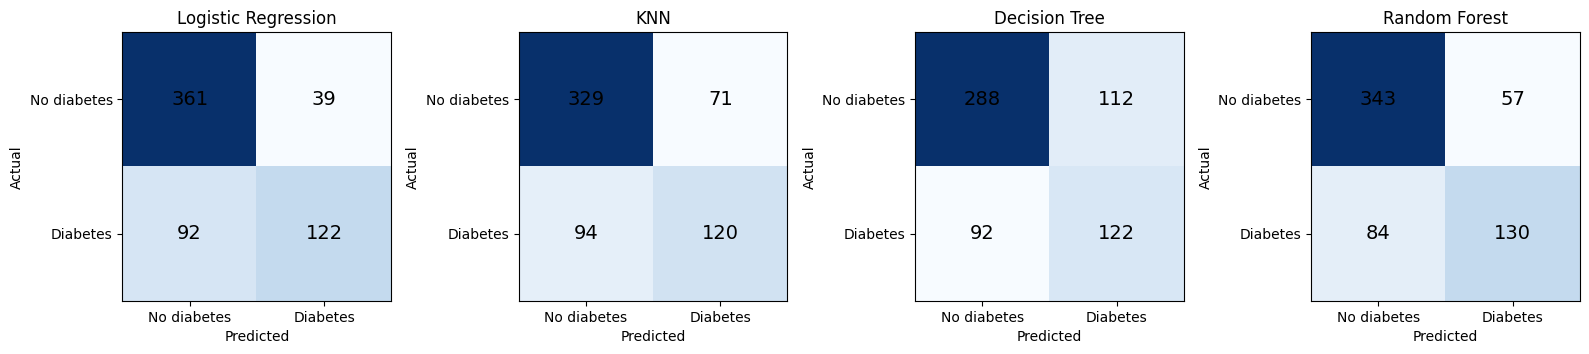

In [8]:
plt.figure(figsize=(16, 4))
for i, (name, p) in enumerate(probas.items()):
    pred = (p >= 0.5).astype(int)
    cm = confusion_matrix(y_train, pred)
    plt.subplot(1, 4, i + 1)
    plt.imshow(cm, cmap="Blues")
    for r in range(2):
        for c in range(2):
            plt.text(c, r, cm[r, c], ha="center", va="center", fontsize=14)
    plt.xticks([0, 1], ["No diabetes", "Diabetes"])
    plt.yticks([0, 1], ["No diabetes", "Diabetes"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(name)
plt.tight_layout()
plt.show()

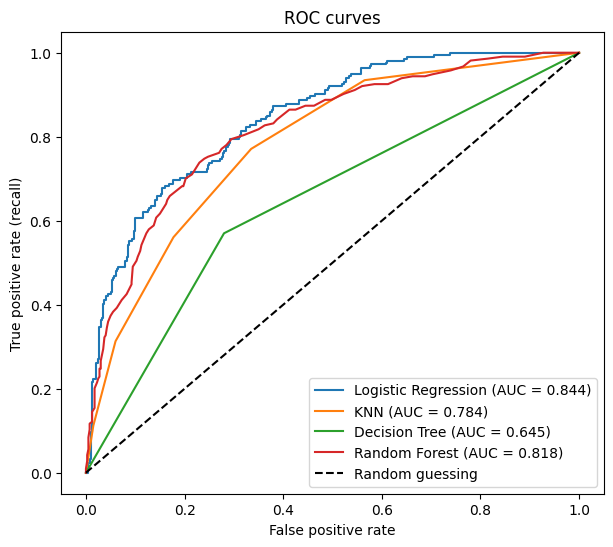

In [9]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_train, p)
    auc = roc_auc_score(y_train, p)
    plt.plot(fpr, tpr, label=name + " (AUC = " + str(round(auc, 3)) + ")")

plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves")
plt.legend()
plt.show()

In [10]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grids = {
    "Logistic Regression": {
        "C": [0.01, 0.1, 1.6, 10, 100],
        "class_weight": [None, "balanced"],
        'solver': ['lbfgs']
    },
    "KNN": {
        "n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
        "weights": ["uniform", "distance"],
        "p": [1, 2]
    },
    "Decision Tree": {
        "max_depth": [2, 3, 4, 5, 6, 8, None],
        "min_samples_leaf": [1, 5, 10, 20],
        "class_weight": [None, "balanced"]
    },
    "Random Forest": {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [5, 10],
    "class_weight": [None, "balanced"],
    "max_features": ["sqrt"]
    }
}

In [11]:
searches = {}

for name, model in models.items():
    gs = GridSearchCV(model, param_grids[name], scoring="accuracy", cv=cv)
    gs.fit(X_train, y_train)
    searches[name] = gs
    print(name, "| combinations:", len(gs.cv_results_["params"]),
          "| best Accuracy:", round(gs.best_score_, 4), "|", gs.best_params_)

Logistic Regression | combinations: 10 | best Accuracy: 0.7866 | {'C': 1.6, 'class_weight': None, 'solver': 'lbfgs'}
KNN | combinations: 32 | best Accuracy: 0.772 | {'n_neighbors': 15, 'p': 2, 'weights': 'uniform'}
Decision Tree | combinations: 56 | best Accuracy: 0.7508 | {'class_weight': 'balanced', 'max_depth': 6, 'min_samples_leaf': 20}
Random Forest | combinations: 36 | best Accuracy: 0.7785 | {'class_weight': None, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 300}


In [12]:
results_dt = pd.DataFrame(searches["Logistic Regression"].cv_results_)
top = results_dt[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
print(top.sort_values("rank_test_score").head(5))

                                              params  mean_test_score  \
4  {'C': 1.6, 'class_weight': None, 'solver': 'lb...         0.786605   
6  {'C': 10, 'class_weight': None, 'solver': 'lbf...         0.786592   
8  {'C': 100, 'class_weight': None, 'solver': 'lb...         0.786592   
2  {'C': 0.1, 'class_weight': None, 'solver': 'lb...         0.783340   
0  {'C': 0.01, 'class_weight': None, 'solver': 'l...         0.767106   

   std_test_score  rank_test_score  
4        0.019300                1  
6        0.021423                2  
8        0.021423                2  
2        0.022092                4  
0        0.013093                5  


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = []

for name, gs in searches.items():

    best_model = gs.best_estimator_

    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).round(4)

print(results_df)

                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
0  Logistic Regression    0.7078     0.6000  0.5000    0.5455   0.8128  0.6726
1                  KNN    0.7468     0.6667  0.5556    0.6061   0.8044  0.6572
2        Decision Tree    0.7468     0.6190  0.7222    0.6667   0.8049  0.6048
3        Random Forest    0.7338     0.6667  0.4815    0.5591   0.8117  0.6940


In [14]:
# Selected Decision Tree as the model


In [15]:
# Treshold Tuning

best_dt = searches["Decision Tree"].best_estimator_

In [16]:
# Generate probability predictions

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone

# Get the best tuned Decision Tree
best_dt = searches["Decision Tree"].best_estimator_

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate out-of-fold probability predictions
y_prob_oof = cross_val_predict(
    clone(best_dt),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

print("OOF predictions generated:", len(y_prob_oof))



OOF predictions generated: 614


In [17]:
prob_df = pd.DataFrame({
    "Actual": y_train,
    "Diabetes_Probability": y_prob_oof
})

print(prob_df.head(10))

   Actual  Diabetes_Probability
0       0              0.000000
1       0              0.164567
2       0              0.000000
3       0              0.541684
4       0              0.000000
5       1              1.000000
6       1              0.870748
7       1              0.981273
8       0              0.000000
9       0              0.000000


In [18]:
thresholds = np.arange(0.1, 0.91, 0.05)

results = []

for threshold in thresholds:

    y_pred = (y_prob_oof >= threshold).astype(int)

    precision = precision_score(y_train, y_pred, zero_division=0)
    recall = recall_score(y_train, y_pred, zero_division=0)
    f1 = f1_score(y_train, y_pred, zero_division=0)

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

threshold_df = pd.DataFrame(results)

print(threshold_df.round(4))

    Threshold  Precision  Recall  F1-Score
0        0.10     0.4593  0.9486    0.6189
1        0.15     0.4738  0.9299    0.6278
2        0.20     0.4761  0.8832    0.6187
3        0.25     0.4973  0.8738    0.6339
4        0.30     0.5113  0.8458    0.6373
5        0.35     0.5202  0.8411    0.6429
6        0.40     0.5882  0.7944    0.6759
7        0.45     0.5882  0.7944    0.6759
8        0.50     0.6169  0.7523    0.6779
9        0.55     0.6276  0.7009    0.6623
10       0.60     0.6422  0.6542    0.6481
11       0.65     0.6341  0.6075    0.6205
12       0.70     0.6444  0.5421    0.5888
13       0.75     0.6364  0.3925    0.4855
14       0.80     0.6695  0.3692    0.4759
15       0.85     0.6915  0.3037    0.4221
16       0.90     0.7463  0.2336    0.3559


In [25]:
best_row=threshold_df.loc[
    threshold_df["F1-Score"].idxmax()
]

best_threshold=best_row["Threshold"]
print("Best Threshold:", best_threshold)
print(best_row)

Best Threshold: 0.5
Threshold    0.500000
Precision    0.616858
Recall       0.752336
F1-Score     0.677895
Name: 8, dtype: float64


In [26]:
# Retraining the model(Decision tree)

final_dt=best_dt

final_dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_fea

In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Predict probabilities
y_test_prob = final_dt.predict_proba(X_test)[:, 1]

# Apply selected threshold
y_test_pred = (y_test_prob >= best_threshold).astype(int)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1-Score:", f1_score(y_test, y_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))
print("PR-AUC (Average Precision):", average_precision_score(y_test, y_test_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Accuracy: 0.7467532467532467
Precision: 0.6190476190476191
Recall: 0.7222222222222222
F1-Score: 0.6666666666666666
ROC-AUC: 0.8049074074074074
PR-AUC (Average Precision): 0.6048251876527699

Confusion Matrix:
[[76 24]
 [15 39]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.76      0.80       100
           1       0.62      0.72      0.67        54

    accuracy                           0.75       154
   macro avg       0.73      0.74      0.73       154
weighted avg       0.76      0.75      0.75       154

